In [2]:
import pandas as pd 
import geopandas as gpd
import matplotlib.pyplot as plt

import os

print(os.getcwd())
path = "../data/GTFS_KRK_T/stops.txt"
path2 = "../data/GTFS_KRK_T/stop_times.txt"
path3 = "../data/GTFS_KRK_T/trips.txt"
stops = pd.read_csv(path)
stop_times = pd.read_csv(path2)
trips = pd.read_csv(path3)

stops_gpd = gpd.GeoDataFrame(
    stops,
    geometry = gpd.points_from_xy(stops.stop_lon,stops.stop_lat),
    crs = "EPSG:4326"
)
stops_gpd.head()
stop_times.head()



c:\Users\kamil\PythonProjects\projects\klastry_przystanków\notebooks


,trip_id,arrival_time,departure_time,stop_id,stop_sequence,stop_headsign,pickup_type,drop_off_type,shape_dist_traveled,timepoint
0,block_2_trip_2_service_4,06:06:00,06:06:00,stop_213_31119,1,NaN,0,1,0.000,1
1,block_2_trip_2_service_4,06:07:00,06:07:00,stop_213_31129,2,NaN,0,0,0.108,1
2,block_2_trip_2_service_4,06:08:00,06:08:00,stop_214_31329,3,NaN,0,0,0.622,1
3,block_2_trip_2_service_4,06:09:00,06:09:00,stop_216_31929,4,NaN,0,0,1.039,1
4,block_2_trip_2_service_4,06:12:00,06:12:00,stop_219_32229,5,NaN,0,0,1.630,1


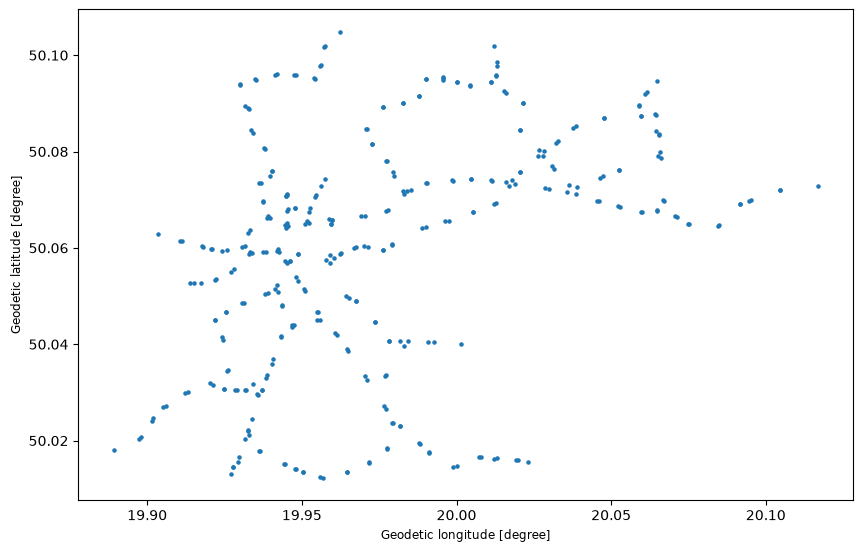

In [3]:
stops_gpd.plot(figsize=(10,8),markersize=5)
plt.show()

<Axes: xlabel='stop_id'>

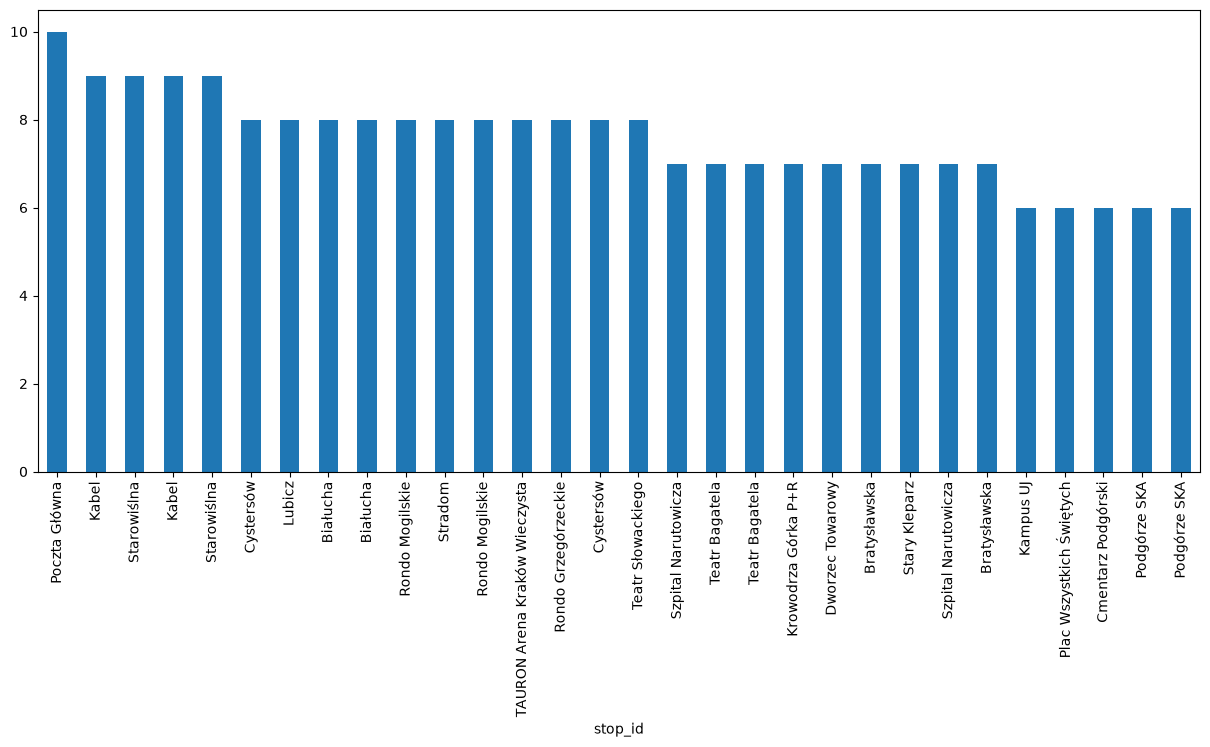

In [5]:
stops_merged = stops.merge(stop_times,how="inner",on="stop_id")
stops_merged = stops_merged.merge(trips,how="inner",on="trip_id")
stops_grouped = stops_merged.groupby(by="stop_id")

stops_unique = stops_grouped["route_id"].nunique()
top30 = stops_unique.sort_values(ascending=False).head(30)
stop_names = stops.set_index("stop_id")["stop_name"]
top30.index = top30.index.map(stop_names)
#stops_unique["stop_id"].value_counts(sort=True)
top30.plot(
    kind="bar",
    figsize=(15,6),
)

In [6]:
stops_gpd["number_of_routes"] = stops_gpd["stop_id"].map(stops_unique)
stops_gpd.head()

only_one_route = stops_gpd[stops_gpd["number_of_routes"] == 1.0]


stops_gpd = stops_gpd.to_crs(epsg=2180)

stops_gpd.to_file("../data/processed/stops_with_routes.gpkg",driver="GPKG")